In [30]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [31]:
X = np.array([
    [0, 0],
    [1, 0],
    [0, 1],
    [1, 1],
])

y = np.array([0, 1, 1, 0])

In [1]:
def sigmoid(w):
    return 1 / (1 + np.exp(-w))

def relu(w):
    return np.maximum(w, 0)

def softmax(w):
    sumofexpo = np.sum(np.exp(w), axis=1, keepdims=True)
    softmax_result = [np.exp(x) / sumofexpo for x in w]
    return softmax_result 

class NDK_DENSE:

    def __init__(self, n_inputs, n_neurons, activation_fn="sigmoid"):
        if activation_fn == "relu":
            self.weights = np.random.randn(n_inputs, n_neurons) * np.sqrt(2 / n_inputs)
            self.biases = np.full((1, n_neurons), 0.01)
        else:
            self.weights = np.random.randn(n_inputs, n_neurons) * 0.1
            self.biases = np.zeros((1, n_neurons))
            
        self.activation_fn = activation_fn
    
    def feed(self, X):
        self.Z = np.dot(X, self.weights) + self.biases
        self.X = X

        if self.activation_fn == "sigmoid":
            self.A = sigmoid(self.Z)
        elif self.activation_fn == "relu":
            self.A = relu(self.Z)

        return self.A
    
    def binary_loss(self, y_pred, y):
        epsilon = 1e-9
        y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
        return -np.mean(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
    
    # dA is the error (y_pred - y) for output layer, and for hidden layer its the backpropagated error from the next layer
    def backward(self, dA, learning_rate, is_output=False):
        if is_output and self.activation_fn == "sigmoid":
            dZ = dA
        else:
            if self.activation_fn == "sigmoid":
                dZ = dA * (self.A * (1 - self.A))
            elif self.activation_fn == "relu":
                dZ = dA * (self.Z > 0)

        m = self.X.shape[0]
        dW = (1 / m) * np.dot(self.X.T, dZ)
        db = (1 / m) * np.sum(dZ, axis=0, keepdims=True)
        dA_prev = np.dot(dZ, self.weights.T)

        self.weights -= learning_rate * dW
        self.biases -= learning_rate * db

        return dA_prev

In [ ]:
y_train = y.reshape(-1, 1)

hidden = NDK_DENSE(2, 2, activation_fn="relu")
output = NDK_DENSE(2, 1, activation_fn="sigmoid")

# Save initial params for visualization (before training)
hidden_weights_init = hidden.weights.copy()
hidden_biases_init = hidden.biases.copy()
output_weights_init = output.weights.copy()
output_biases_init = output.biases.copy()

epochs = 20000
learning_rate = 0.1

for epoch in range(epochs):
    A1 = hidden.feed(X)
    A2 = output.feed(A1)

    loss = output.binary_loss(A2, y_train)

    # For sigmoid + binary cross-entropy, dZ at output is (A2 - y)
    
    # A2 is predicted and y_train is true label
    # so its basically error  
    dz2 = A2 - y_train
    
    # dz2 is A2 - y, which is the gradient of the loss with respect to the output layer's pre-activation values.
    dA1 = output.backward(dz2, learning_rate=learning_rate, is_output=True)
    hidden.backward(dA1, learning_rate=learning_rate)

    if epoch % 2000 == 0:
        print(f"epoch={epoch:5d}, loss={loss:.6f}")

epoch=    0, loss=0.693721
epoch= 2000, loss=0.020056
epoch= 4000, loss=0.006692
epoch= 6000, loss=0.003875
epoch= 8000, loss=0.002697
epoch=10000, loss=0.002055
epoch=12000, loss=0.001656
epoch=14000, loss=0.001383
epoch=16000, loss=0.001185
epoch=18000, loss=0.001036


In [34]:
probs = output.feed(hidden.feed(X))
preds = (probs > 0.5).astype(int)

print("Probabilities:\n", probs.ravel())
print("Predictions:\n", preds.ravel())
print("Targets:\n", y_train.ravel())

Probabilities:
 [4.20939069e-04 9.97292524e-01 9.99775708e-01 3.20385029e-04]
Predictions:
 [0 1 1 0]
Targets:
 [0 1 1 0]


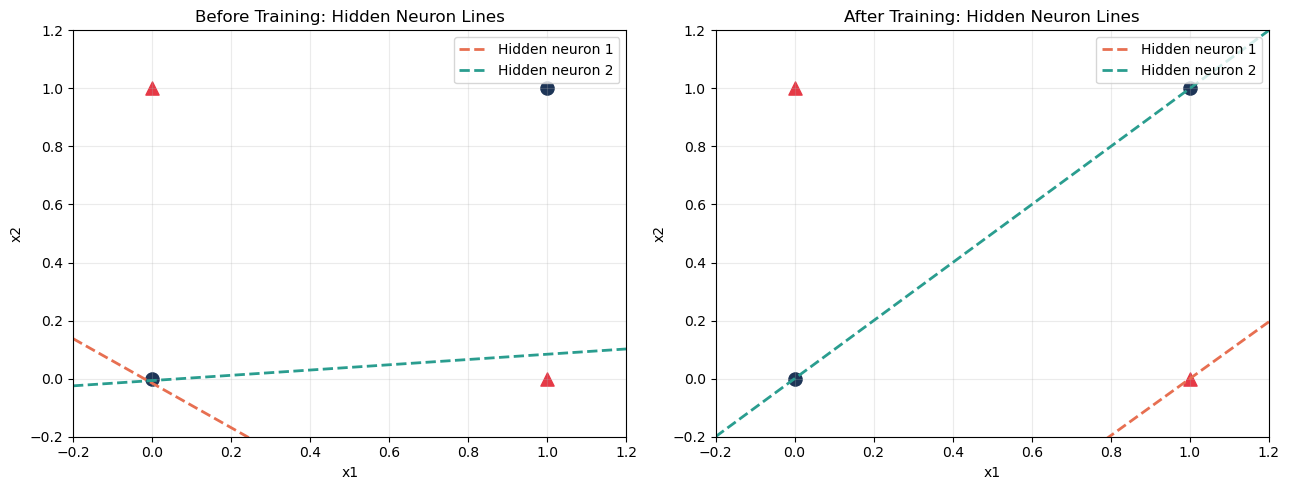

In [35]:
def forward_with_params(X_input, W1, b1, W2, b2):
    Z1 = np.dot(X_input, W1) + b1
    A1 = np.maximum(0, Z1)
    Z2 = np.dot(A1, W2) + b2
    A2 = 1 / (1 + np.exp(-Z2))
    return Z1, A1, Z2, A2

def plot_hidden_neuron_lines(ax, W, b, title):
    x1_vals = np.linspace(-0.2, 1.2, 200)
    colors = ["#e76f51", "#2a9d8f"]

    for j in range(W.shape[1]):
        w1 = W[0, j]
        w2 = W[1, j]
        bj = b[0, j]

        if abs(w2) < 1e-8:
            if abs(w1) > 1e-8:
                x_const = -bj / w1
                ax.axvline(x_const, color=colors[j], linestyle="--", linewidth=2, label=f"Hidden neuron {j+1}")
        else:
            x2_vals = -(w1 * x1_vals + bj) / w2
            ax.plot(x1_vals, x2_vals, linestyle="--", linewidth=2, color=colors[j], label=f"Hidden neuron {j+1}")

    for point, label in zip(X, y):
        if label == 0:
            ax.scatter(point[0], point[1], c="#1d3557", s=90, marker="o")
        else:
            ax.scatter(point[0], point[1], c="#e63946", s=90, marker="^")

    ax.set_xlim(-0.2, 1.2)
    ax.set_ylim(-0.2, 1.2)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_hidden_neuron_lines(axes[0], hidden_weights_init, hidden_biases_init, "Before Training: Hidden Neuron Lines")
plot_hidden_neuron_lines(axes[1], hidden.weights, hidden.biases, "After Training: Hidden Neuron Lines")
plt.tight_layout()
plt.show()

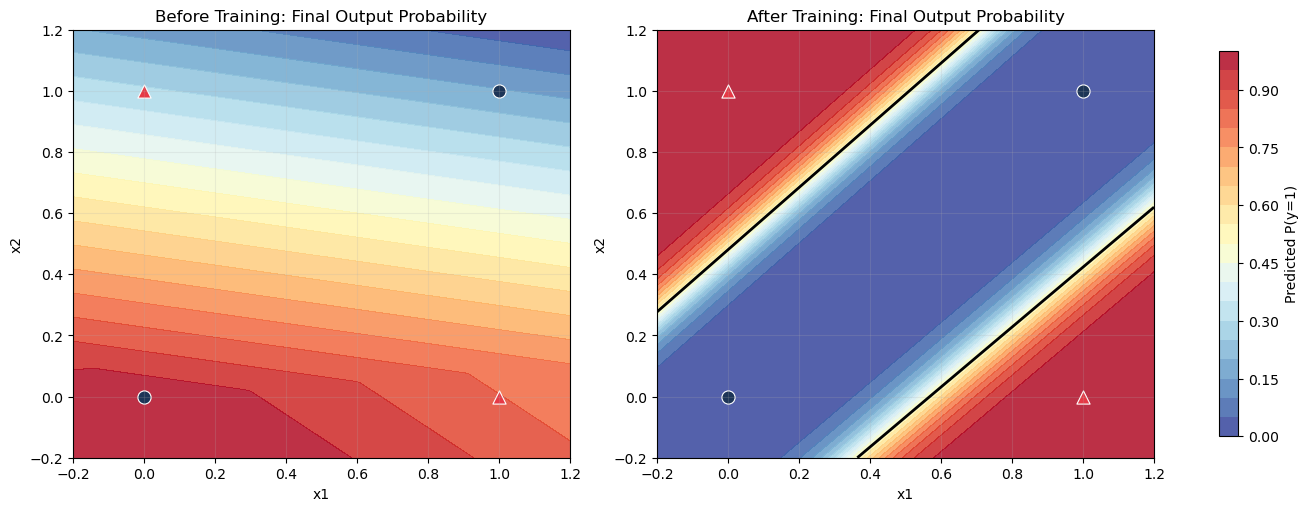

In [36]:
# Build grid to visualize final output layer decision surface
x1_grid = np.linspace(-0.2, 1.2, 220)
x2_grid = np.linspace(-0.2, 1.2, 220)
xx, yy = np.meshgrid(x1_grid, x2_grid)
grid_points = np.c_[xx.ravel(), yy.ravel()]

_, _, _, prob_init_grid = forward_with_params(
    grid_points, hidden_weights_init, hidden_biases_init, output_weights_init, output_biases_init
)
_, _, _, prob_trained_grid = forward_with_params(
    grid_points, hidden.weights, hidden.biases, output.weights, output.biases
)

prob_init_grid = prob_init_grid.reshape(xx.shape)
prob_trained_grid = prob_trained_grid.reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

axes[0].contourf(xx, yy, prob_init_grid, levels=20, cmap="RdYlBu_r", alpha=0.85)
axes[0].contour(xx, yy, prob_init_grid, levels=[0.5], colors="black", linewidths=2)
axes[0].set_title("Before Training: Final Output Probability")
axes[0].set_xlabel("x1")
axes[0].set_ylabel("x2")
axes[0].set_xlim(-0.2, 1.2)
axes[0].set_ylim(-0.2, 1.2)
axes[0].grid(alpha=0.2)

c1 = axes[1].contourf(xx, yy, prob_trained_grid, levels=20, cmap="RdYlBu_r", alpha=0.85)
axes[1].contour(xx, yy, prob_trained_grid, levels=[0.5], colors="black", linewidths=2)
axes[1].set_title("After Training: Final Output Probability")
axes[1].set_xlabel("x1")
axes[1].set_ylabel("x2")
axes[1].set_xlim(-0.2, 1.2)
axes[1].set_ylim(-0.2, 1.2)
axes[1].grid(alpha=0.2)

for ax in axes:
    for point, label in zip(X, y):
        if label == 0:
            ax.scatter(point[0], point[1], c="#1d3557", s=90, marker="o", edgecolors="white", linewidths=0.8)
        else:
            ax.scatter(point[0], point[1], c="#e63946", s=90, marker="^", edgecolors="white", linewidths=0.8)

fig.colorbar(c1, ax=axes, shrink=0.9, label="Predicted P(y=1)")
plt.show()